# Credit Pre-Screening Engine — Loan Intake Optimisation

**Calibo AI Academy · Phase 2 — Mini Use Case 02 · KLU Batch**  
**Stage:** Phase 1 — Problem Framing and CBIM Problem Canvas

> **Working rule:** Every analysis section must contain both runnable code and a plain-English interpretation. We will not claim a result until it has been calculated from the provided dataset.

## Project goal
Use six months of historical analyst decisions to investigate whether a model can identify *high-confidence historical declines* and reduce the manual review queue while respecting the bank's stated risk limit.

**Important boundary:** The assignment describes the dataset as simulated. The `decision` column records a historical analyst decision. It is not a verified outcome such as whether a customer later defaulted, repaid, or was truly creditworthy. Therefore, this project evaluates how well a model reproduces historical decisions; it does not prove that a model can safely make real lending decisions.

## CBIM Problem Canvas

### Situation (S)
A mid-sized Indian private bank processes unsecured personal-loan applications. About 3,000 applications arrive each month, and a manual review takes an analyst roughly 25 minutes per application.

### Complication (C)
A substantial share of applications are declined, including cases that may be clear-cut from the outset. Manual review time is spent on cases that might be identified earlier, but an automated decline can wrongly turn away an applicant who would otherwise have been approved. The bank also needs evidence that outcomes are not unfairly distributed across applicant groups.

### Question (Q)
Can a model trained on six months of historical decisions identify a subset of applications that could be removed from the manual-review queue while keeping the share of historically approved applicants among those auto-declined at **5% or less**, and how much review time could that save?

### SSOT (Single Source of Truth)
The supplied **simulated** CSV is the source of records for this analysis. Each row represents one application, and `decision` is the final decision recorded by the historical credit team. This label represents past policy decisions, not future repayment/default or an independently verified definition of creditworthiness.

### Success definition
On the specified stratified 80/20 split (`random_state=42`), evaluate a logistic-regression model and inspect thresholds 0.50, 0.60, 0.70, 0.80, 0.85, 0.90 and 0.95. Among thresholds where no more than 5% of auto-declined applications were historically `Approved`, choose the threshold that auto-declines the largest share. Report the confusion matrix and the number of false auto-declines, then convert the selected coverage into monthly applications and analyst hours. If no tested threshold meets the limit, state that clearly rather than relaxing the rule silently.

### Primary stakeholder
The Credit Policy Analyst is the primary stakeholder and must explain the recommendation to the Head of Retail Lending. Credit analysts and loan applicants are also directly affected by the policy decision.

## Key modelling decisions to preserve

1. **The business risk matters more than accuracy alone.** We will report how many cases predicted for decline were actually `Approved` in the historical data.
2. **Missing credit scores are meaningful.** The assignment says to retain applicants with no score and encode a separate `is_ntc` indicator.
3. **Gender is excluded from the model features but included in the fairness audit.** Excluding it does not by itself establish fairness; other variables may act as proxies.
4. **Threshold findings are retrospective.** Because the assignment asks for threshold selection on test-set probabilities, we will follow its requested analysis and clearly note that a production evaluation should use validation data for threshold choice and preserve an untouched final test set.
5. **No deployment claim.** The file is simulated, and approval labels reflect existing decisions. Any real deployment would require validation on representative real data, governance, monitoring, and human oversight.

## Project roadmap

| Phase | Assignment section | Output |
|---|---|---|
| 1 | CBIM canvas | Business framing and success rule — completed here |
| 2 | 5.1 | Data audit, missingness investigation, justified cleaning |
| 3 | 5.2 | Approval rates by credit-score band and employment type |
| 4 | 5.3 | FOIR, loan-to-income, new-to-credit flag, FOIR analysis |
| 5 | 5.4 | Logistic-regression pipeline, evaluation, coefficient interpretation |
| 6 | 5.5 | Threshold table/chart and monthly workload estimate |
| 7 | 5.6 | Gender fairness and proxy-variable analysis |
| 8 | 5.7 + deliverables | Credit Policy Briefing and one-page insight summary |

**Do not fill in numerical conclusions in advance.** We will calculate each result from the CSV and then write its interpretation.

## Environment setup

The assignment uses Python, Jupyter, Pandas, NumPy, Matplotlib, Seaborn, and scikit-learn. Install missing packages from a terminal if required:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

Keep this notebook and the CSV in the same folder. The uploaded CSV filename currently includes ` 1`; the loading code in the next phase will handle the supplied filename and the assignment's expected filename.

In [1]:
# Phase 1 environment check — no data analysis yet
import sys

print("Python:", sys.version.split()[0])

try:
    import pandas as pd
    import numpy as np
    import matplotlib
    import seaborn as sns
    import sklearn
    print("pandas:", pd.__version__)
    print("NumPy:", np.__version__)
    print("Matplotlib:", matplotlib.__version__)
    print("Seaborn:", sns.__version__)
    print("scikit-learn:", sklearn.__version__)
    print("Environment check passed.")
except ImportError as exc:
    print("A required package is missing:", exc)
    print("Install dependencies with: pip install pandas numpy matplotlib seaborn scikit-learn jupyter")
    raise

Python: 3.13.5
pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
scikit-learn: 1.9.1
Environment check passed.


## Phase 1 checkpoint

- [x] The decision to be supported is stated in business language.
- [x] The historical target and its limitations are defined.
- [x] The 5% false-auto-decline guardrail is explicit.
- [x] Affected stakeholders and fairness concerns are recorded.
- [ ] Phase 2: inspect the raw data, quantify data-quality issues, and justify every cleaning decision.

**Presentation tip:** Start by explaining the business risk and the 5% guardrail. It shows that the model is being designed around a lending decision, not just around a high accuracy score.

In [2]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\abhin\Desktop\CALIBO\USE-CASE-2\.venv\Scripts\python.exe
Python version: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [3]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All required libraries are working!")

Pandas: 3.1.0
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1
All required libraries are working!


**Phase 2 — Data audit and cleaning**

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# The assignment uses this filename. The second name supports the uploaded copy
# whose filename includes " 1"; the wildcard helps if your operating system adds a suffix.
candidates = [
    Path("MUC02_Credit_PreScreening_Dataset.csv"),
    Path("MUC02_Credit_PreScreening_Dataset 1.csv"),
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    matches = sorted(Path.cwd().glob("MUC02_Credit_PreScreening_Dataset*.csv"))
    if matches:
        data_path = matches[0]

if data_path is None:
    raise FileNotFoundError(
        "Could not find the dataset. Place MUC02_Credit_PreScreening_Dataset.csv "
        "in the same folder as this notebook, then rerun this cell."
    )

df_raw = pd.read_csv(data_path)
print(f"Loaded: {data_path.resolve()}")
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded: C:\Users\abhin\Desktop\CALIBO\USE-CASE-2\MUC02_Credit_PreScreening_Dataset 1.csv
Shape: 12,000 rows × 19 columns


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


**Inspect shape, columns, data types, and target balance**

In [5]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.rename("dtype").to_frame())

print("\nDuplicate application IDs:", df_raw["application_id"].duplicated().sum())
print("Duplicate full rows:", df_raw.duplicated().sum())

print("\nHistorical decision counts:")
decision_counts = df_raw["decision"].value_counts(dropna=False)
display(decision_counts.rename("applications").to_frame())

print("\nHistorical decision percentages:")
display((df_raw["decision"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).rename("percent").to_frame())

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']

Data types:


,dtype
application_id,str
application_date,str
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,float64



Duplicate application IDs: 0
Duplicate full rows: 0

Historical decision counts:


,applications
decision,
Approved,6353
Declined,5647



Historical decision percentages:


,percent
decision,
Approved,52.94
Declined,47.06


**Interpretation to record: The file contains 12,000 applications. The target is not perfectly balanced, but neither class is rare: approximately 52.9% are Approved and 47.1% are Declined. Accuracy alone will not be enough, because the business requirement focuses on how often an auto-decline would be wrong.**

"**Audit missing values**"

*Count missing values and calculate their percentage by column. Missingness is not automatically a data error: the assignment specifically tells us that a blank credit score may represent an applicant with no credit histor*

In [6]:
missing_audit = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
})
missing_audit = missing_audit.loc[missing_audit["missing_count"].gt(0)].sort_values(
    "missing_count", ascending=False
)
display(missing_audit)

,missing_count,missing_percent
credit_score,1039,8.66
monthly_income,441,3.68


*Investigate missing monthly income by employment type
The assignment asks us to identify which employment groups are affected. Counts alone can be misleading because the groups have different sizes, so we compare both the number missing and the missing rate within each group.*

,applicants,missing_income,median_observed_income,missing_rate_percent
employment_type,,,,
Business Owner,1749,227,69500.0,12.98
Self-Employed Professional,1428,154,75000.0,10.78
Salaried,7057,49,50000.0,0.69
Gig / Contract,1766,11,28000.0,0.62


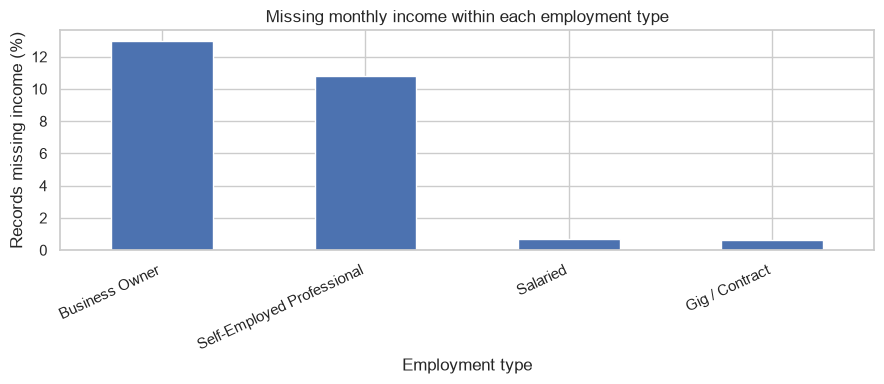

In [7]:
income_missing_audit = (
    df_raw.groupby("employment_type", dropna=False)
    .agg(
        applicants=("application_id", "size"),
        missing_income=("monthly_income", lambda s: s.isna().sum()),
        median_observed_income=("monthly_income", "median"),
    )
)
income_missing_audit["missing_rate_percent"] = (
    income_missing_audit["missing_income"] / income_missing_audit["applicants"] * 100
).round(2)
income_missing_audit = income_missing_audit.sort_values("missing_rate_percent", ascending=False)
display(income_missing_audit)

ax = income_missing_audit["missing_rate_percent"].plot(kind="bar", figsize=(9, 4))
ax.set_title("Missing monthly income within each employment type")
ax.set_xlabel("Employment type")
ax.set_ylabel("Records missing income (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


**we found: Missing income is concentrated proportionally among Business Owners and Self-Employed Professionals. Because income is usually right-skewed and these groups have different income distributions, using a single overall mean would be a weak default. For exploratory analysis, we will impute missing income with the median of the same employment type. For model evaluation, we will recompute imputation values from the training split only, to avoid test-set leakage.**

**#Validate the missing-credit-score pattern**

**Check whether missing credit_score values line up with credit_history_months == 0. This determines whether we should treat the blank score as a meaningful category rather than delete the row.**

In [8]:
score_missing = df_raw["credit_score"].isna()
no_history = df_raw["credit_history_months"].eq(0)

print(f"Missing credit scores: {score_missing.sum():,} ({score_missing.mean() * 100:.2f}%)")
print("Missing-score rows where credit_history_months == 0:", (score_missing & no_history).sum())
print("Missing-score rows where credit_history_months > 0:", (score_missing & ~no_history).sum())
print("Rows with credit_history_months == 0 but a non-missing score:", (~score_missing & no_history).sum())

display(pd.crosstab(
    df_raw["credit_score"].isna().map({True: "Score missing", False: "Score present"}),
    df_raw["credit_history_months"].eq(0).map({True: "No credit history", False: "History > 0"}),
    margins=True,
))

Missing credit scores: 1,039 (8.66%)
Missing-score rows where credit_history_months == 0: 1039
Missing-score rows where credit_history_months > 0: 0
Rows with credit_history_months == 0 but a non-missing score: 0


credit_history_months,History > 0,No credit history,All
credit_score,,,
Score missing,0,1039,1039
Score present,10961,0,10961
All,10961,1039,12000


**Decision: The dataset shows a consistent pattern: every missing credit score has zero months of credit history, and no row with a score has zero months of history. We will keep these applications and define is_ntc = 1 when the score is missing. During model training, the numeric credit_score will be imputed using the median calculated from the training data; is_ntc will preserve the distinction between a genuine score and an imputed value.**

**Investigate implausibly high monthly income**

**The assignment asks us to investigate the maximum income and propose an explanation. We will inspect high values by employment type rather than automatically winsorising or deleting them. A value that is unusual for a salaried employee may be legitimate for a business owner.**

In [9]:
income_percentiles = df_raw["monthly_income"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.995, 0.999]
).to_frame("monthly_income_INR")
display(income_percentiles)

high_income = df_raw.loc[df_raw["monthly_income"].gt(300_000), [
    "application_id", "employment_type", "monthly_income", "decision"
]].copy()
high_income["divisible_by_12"] = np.isclose(high_income["monthly_income"] % 12, 0)
high_income["income_if_annual_value_INR_per_month"] = high_income["monthly_income"] / 12
print(f"Records with reported monthly income > ₹300,000: {len(high_income)}")
display(high_income.sort_values("monthly_income", ascending=False))

print("\nCounts by employment type and divisibility by 12:")
display(pd.crosstab(high_income["employment_type"], high_income["divisible_by_12"], margins=True))

,monthly_income_INR
count,1.155900e+04
mean,6.031486e+04
std,4.889083e+04
min,1.200000e+04
50%,5.050000e+04
90%,1.060000e+05
95%,1.300000e+05
99%,1.910000e+05
99.5%,2.342100e+05
99.9%,5.778240e+05


Records with reported monthly income > ₹300,000: 28


,application_id,employment_type,monthly_income,decision,divisible_by_12,income_if_annual_value_INR_per_month
1467,APP101468,Salaried,1656000.0,Declined,True,138000.000000
300,APP100301,Salaried,1254000.0,Approved,True,104500.000000
2493,APP102494,Salaried,1212000.0,Approved,True,101000.000000
589,APP100590,Salaried,1068000.0,Declined,True,89000.000000
9849,APP109850,Salaried,990000.0,Declined,True,82500.000000
1848,APP101849,Salaried,984000.0,Approved,True,82000.000000
2488,APP102489,Salaried,972000.0,Approved,True,81000.000000
4010,APP104011,Salaried,900000.0,Approved,True,75000.000000
4898,APP104899,Salaried,870000.0,Declined,True,72500.000000
9261,APP109262,Salaried,702000.0,Approved,True,58500.000000



Counts by employment type and divisibility by 12:


divisible_by_12,False,True,All
employment_type,,,
Business Owner,1,2,3
Salaried,0,22,22
Self-Employed Professional,2,1,3
All,3,25,28


**Evidence-based interpretation:**There are 22 Salaried records above ₹300,000, and every one is exactly divisible by 12. Dividing these values by 12 produces monthly incomes from ₹26,500 to ₹138,000, a much more plausible range. This pattern is consistent with annual salary being entered in a monthly-income field. The file itself does not contain a source-system flag proving this, so we will document the correction as a data-quality assumption and retain both the original value and a boolean flag. Other very high incomes from Business Owners or Self-Employed Professionals will not be automatically changed because high monthly earnings can be plausible for those groups.

**Evidence-based interpretation: There are 22 Salaried records above ₹300,000, and every one is exactly divisible by 12. Dividing these values by 12 produces monthly incomes from ₹26,500 to ₹138,000, a much more plausible range. This pattern is consistent with annual salary being entered in a monthly-income field. The file itself does not contain a source-system flag proving this, so we will document the correction as a data-quality assumption and retain both the original value and a boolean flag. Other very high incomes from Business Owners or Self-Employed Professionals will not be automatically changed because high monthly earnings can be plausible for those groups.**

**Apply and document cleaning decisions**

In [10]:
# Start from an unchanged source snapshot.
df_clean = df_raw.copy()

# Preserve original income values for audit and reversibility.
df_clean["monthly_income_original"] = df_clean["monthly_income"]

# Narrow, documented heuristic: Salaried income > ₹300,000 and exactly divisible by 12.
income_unit_suspected = (
    df_clean["employment_type"].eq("Salaried")
    & df_clean["monthly_income"].gt(300_000)
    & np.isclose(df_clean["monthly_income"] % 12, 0)
)
df_clean["income_unit_suspected"] = income_unit_suspected

df_clean.loc[income_unit_suspected, "monthly_income"] = (
    df_clean.loc[income_unit_suspected, "monthly_income"] / 12
)

# Preserve the no-score state before model-specific numeric imputation.
df_clean["is_ntc"] = df_clean["credit_score"].isna().astype(int)

# Exploratory-analysis copy: impute missing income using employment-type medians.
# These full-data medians are for EDA only; do not use this copy for test-set model evaluation.
df_eda = df_clean.copy()
income_medians_by_employment = df_eda.groupby("employment_type")["monthly_income"].median()
df_eda["monthly_income"] = df_eda["monthly_income"].fillna(
    df_eda["employment_type"].map(income_medians_by_employment)
)

print("Flagged suspected annual-income records:", int(df_clean["income_unit_suspected"].sum()))
print("Missing monthly_income before imputation:", int(df_clean["monthly_income"].isna().sum()))
print("Missing monthly_income in EDA copy after imputation:", int(df_eda["monthly_income"].isna().sum()))
print("Missing credit_score kept for model pipeline:", int(df_clean["credit_score"].isna().sum()))
print("New-to-credit applicants flagged:", int(df_clean["is_ntc"].sum()))

display(df_clean.loc[df_clean["income_unit_suspected"], [
    "application_id", "employment_type", "monthly_income_original", "monthly_income", "income_unit_suspected"
]].sort_values("monthly_income_original"))

Flagged suspected annual-income records: 22
Missing monthly_income before imputation: 441
Missing monthly_income in EDA copy after imputation: 0
Missing credit_score kept for model pipeline: 1039
New-to-credit applicants flagged: 1039


,application_id,employment_type,monthly_income_original,monthly_income,income_unit_suspected
5090,APP105091,Salaried,318000.0,26500.0,True
5907,APP105908,Salaried,324000.0,27000.0,True
2127,APP102128,Salaried,354000.0,29500.0,True
6901,APP106902,Salaried,396000.0,33000.0,True
11594,APP111595,Salaried,396000.0,33000.0,True
9388,APP109389,Salaried,402000.0,33500.0,True
7983,APP107984,Salaried,432000.0,36000.0,True
1984,APP101985,Salaried,438000.0,36500.0,True
6909,APP106910,Salaried,444000.0,37000.0,True
595,APP100596,Salaried,546000.0,45500.0,True


**Validate the cleaned data**

In [11]:
validation = pd.DataFrame({
    "check": [
        "Row count preserved",
        "Original income column preserved",
        "Income corrections flagged",
        "EDA copy has no missing income",
        "Credit-score blanks preserved for modeling",
        "is_ntc equals missing-credit-score flag",
    ],
    "passed": [
        len(df_clean) == len(df_raw),
        "monthly_income_original" in df_clean.columns,
        int(df_clean["income_unit_suspected"].sum()) == 22,
        df_eda["monthly_income"].isna().sum() == 0,
        df_clean["credit_score"].isna().sum() == df_raw["credit_score"].isna().sum(),
        (df_clean["is_ntc"].eq(df_clean["credit_score"].isna().astype(int))).all(),
    ],
})
display(validation)
assert validation["passed"].all(), "A data-cleaning validation check failed."

print("Final shapes — raw:", df_raw.shape, "| cleaned modeling base:", df_clean.shape, "| EDA copy:", df_eda.shape)
print("\nIncome missingness by employment type is filled only in df_eda:")
print(df_eda["monthly_income"].isna().sum(), "missing values")

,check,passed
0,Row count preserved,True
1,Original income column preserved,True
2,Income corrections flagged,True
3,EDA copy has no missing income,True
4,Credit-score blanks preserved for modeling,True
5,is_ntc equals missing-credit-score flag,True


Final shapes — raw: (12000, 19) | cleaned modeling base: (12000, 22) | EDA copy: (12000, 22)

Income missingness by employment type is filled only in df_eda:
0 missing values


*Missing income: 441 rows (3.68%) are missing. The highest within-group missing rates are Business Owner (12.98%) and Self-Employed Professional (10.78%). For exploratory analysis, the notebook uses each employment group's median. Model-time imputation must be learned from training data only.
Missing credit scores: 1,039 rows (8.66%) have no score, and all of them have credit_history_months == 0. Keep them and use is_ntc so “no score” is not confused with an average score.
Unusually high income: 22 Salaried records above ₹300,000 are divisible by 12 and become ₹26,500–₹138,000 per month when divided by 12. This is consistent with annual income being entered in a monthly field. Preserve the original values and the correction flag so the assumption is auditable.
Target balance: 6,353 applications are Approved (52.94%) and 5,647 are Declined (47.06%). We must pay special attention to wrongly auto-declining applicants who were historically approved.*

**Phase 3 — Understand historical approval decisions**

**Objective: Before fitting a model, inspect how the credit team made decisions historically. We will calculate approval rates by the required credit-score bands and by employment type. This is descriptive analysis: the rates show associations in the supplied historical dataset; they do not establish causation or prove future repayment ability.**

**Approval rate by credit-score band**

The assignment requests six score bands plus a separate No score group. We use left-closed intervals so that scores 600–649, for example, fall into the intended band. A missing score is labelled No score rather than being dropped or placed in a numeric band.

,applications,approved,declined,approval_rate_percent,decline_rate_percent
credit_score_band,,,,,
Below 600,246,5,241,2.03,97.97
600–649,933,30,903,3.22,96.78
650–699,2529,822,1707,32.50,67.50
700–749,3377,1836,1541,54.37,45.63
750–799,2526,1950,576,77.20,22.80
800+,1350,1150,200,85.19,14.81
No score,1039,560,479,53.90,46.10


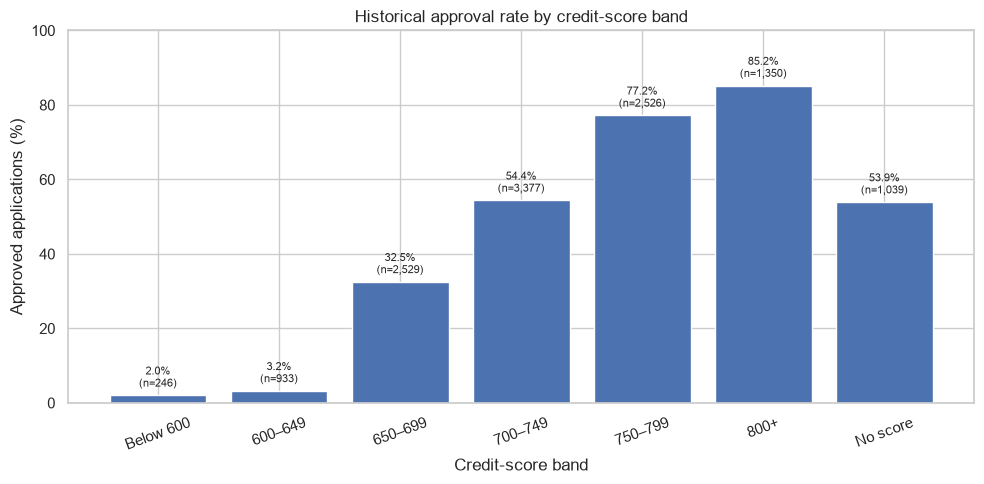

,applications,approved,approval_rate_percent
score_status,,,
Score present,10961,5793,52.85
No score,1039,560,53.90


In [12]:
# Step 5.2A — Approval rates by credit-score band
score_band_labels = [
    "Below 600", "600–649", "650–699", "700–749", "750–799", "800+"
]
score_band_order = score_band_labels + ["No score"]
score_bins = [-np.inf, 600, 650, 700, 750, 800, np.inf]

score_band = pd.cut(
    df_raw["credit_score"],
    bins=score_bins,
    labels=score_band_labels,
    right=False,
    include_lowest=True,
).astype("object")
score_band.loc[df_raw["credit_score"].isna()] = "No score"

df_score_analysis = df_raw.assign(
    credit_score_band=pd.Categorical(
        score_band,
        categories=score_band_order,
        ordered=True,
    )
)

score_summary = (
    df_score_analysis.groupby("credit_score_band", observed=False)
    .agg(
        applications=("application_id", "size"),
        approved=("decision", lambda s: s.eq("Approved").sum()),
        declined=("decision", lambda s: s.eq("Declined").sum()),
    )
)
score_summary["approval_rate_percent"] = (
    score_summary["approved"] / score_summary["applications"] * 100
).round(2)
score_summary["decline_rate_percent"] = (
    score_summary["declined"] / score_summary["applications"] * 100
).round(2)

display(score_summary)
assert score_summary["applications"].sum() == len(df_raw), "Some applications were missed by the score-band analysis."
assert score_summary["approved"].sum() == df_raw["decision"].eq("Approved").sum()
assert score_summary["declined"].sum() == df_raw["decision"].eq("Declined").sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(score_summary.index.astype(str), score_summary["approval_rate_percent"])
ax.set_title("Historical approval rate by credit-score band")
ax.set_xlabel("Credit-score band")
ax.set_ylabel("Approved applications (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=20)
for bar, (_, row) in zip(bars, score_summary.iterrows()):
    ax.annotate(
        f"{row['approval_rate_percent']:.1f}%\n(n={int(row['applications']):,})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8,
    )
plt.tight_layout()
plt.show()

# Directly compare applicants who have a score with applicants who have no score.
score_presence_summary = (
    df_raw.assign(score_status=np.where(df_raw["credit_score"].isna(), "No score", "Score present"))
    .groupby("score_status", sort=False)
    .agg(
        applications=("application_id", "size"),
        approved=("decision", lambda s: s.eq("Approved").sum()),
    )
)
score_presence_summary["approval_rate_percent"] = (
    score_presence_summary["approved"] / score_presence_summary["applications"] * 100
).round(2)
display(score_presence_summary)


**Interpretation — credit score**

Approval is extremely uncommon below 650: the Below 600 band has 5 approvals from 246 applications (2.03%), and the 600–649 band has 30 approvals from 933 applications (3.22%).
Combining those two bands, 35 of 1,179 applicants below 650 were approved (2.97%). This is strong evidence that the historical policy treated scores below 650 as a high-decline segment, although it does not mean every such applicant is unable to repay.
Approval increases to 32.50% for scores 650–699, 54.37% for 700–749, 77.20% for 750–799, and 85.19% for 800+.
The No score group has a 53.90% approval rate (560/1,039), compared with 52.85% for applicants with a recorded score (5,793/10,961). Missing scores should therefore remain a distinct group; they should not automatically be treated as low scores.

**Business implication: Credit score is strongly associated with historical decisions, but this descriptive relationship alone is not sufficient to define a new automatic-decline policy. The model must still be evaluated against the assignment's false-auto-decline constraint.**

**Approval rate by employment type**

,applications,approved,declined,approval_rate_percent,decline_rate_percent
employment_type,,,,,
Salaried,7057,4119,2938,58.37,41.63
Business Owner,1749,895,854,51.17,48.83
Self-Employed Professional,1428,722,706,50.56,49.44
Gig / Contract,1766,617,1149,34.94,65.06


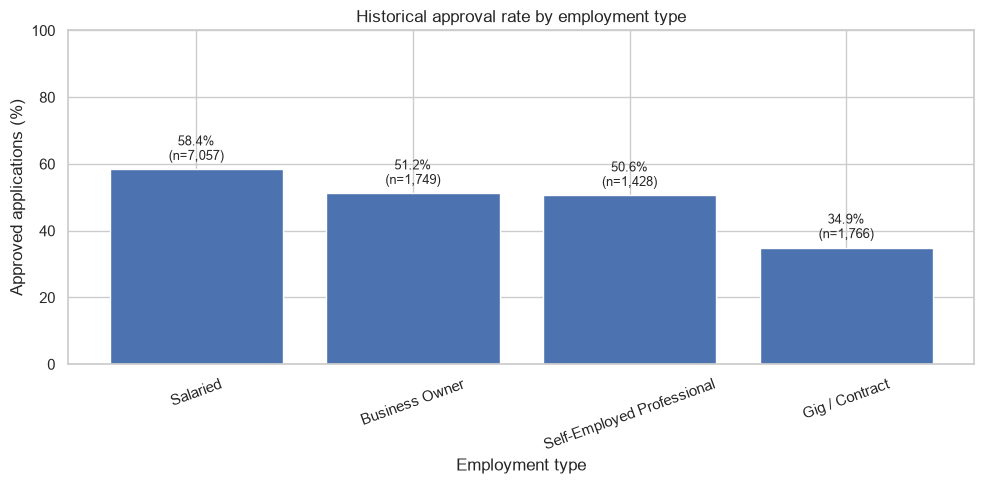

In [13]:
# Step 5.2B — Approval rates by employment type
employment_summary = (
    df_raw.groupby("employment_type", dropna=False)
    .agg(
        applications=("application_id", "size"),
        approved=("decision", lambda s: s.eq("Approved").sum()),
        declined=("decision", lambda s: s.eq("Declined").sum()),
    )
)
employment_summary["approval_rate_percent"] = (
    employment_summary["approved"] / employment_summary["applications"] * 100
).round(2)
employment_summary["decline_rate_percent"] = (
    employment_summary["declined"] / employment_summary["applications"] * 100
).round(2)
employment_summary = employment_summary.sort_values("approval_rate_percent", ascending=False)

display(employment_summary)
assert employment_summary["applications"].sum() == len(df_raw), "Some applications were missed by the employment analysis."

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(employment_summary.index.astype(str), employment_summary["approval_rate_percent"])
ax.set_title("Historical approval rate by employment type")
ax.set_xlabel("Employment type")
ax.set_ylabel("Approved applications (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=20)
for bar, (_, row) in zip(bars, employment_summary.iterrows()):
    ax.annotate(
        f"{row['approval_rate_percent']:.1f}%\n(n={int(row['applications']):,})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9,
    )
plt.tight_layout()
plt.show()


Interpretation — employment type
- Salaried: 4,119 of 7,057 approved (58.37%).
- Business Owner: 895 of 1,749 approved (51.17%).
- Self-Employed Professional: 722 of 1,428 approved (50.56%).
- Gig / Contract: 617 of 1,766 approved (34.94%), the lowest approval rate among the four groups.

**What this tells the analyst: historical decisions differ by employment type, with Gig / Contract applicants having a lower observed approval rate. However, this chart is not an isolated test of employment type: credit score, affordability, delinquencies, and other characteristics may also differ between groups. We should not conclude that employment type itself caused the gap. The difference is a reason to inspect the data carefully and later check whether model errors and auto-decline rates vary across groups.**

**Phase 4 — Engineer affordability features**

Goal: translate income and repayment obligations into features that a credit-policy analyst can interpret. We will calculate the three features requested by the brief: foir, loan_to_income, and is_ntc, then examine how approval rates vary across the required FOIR bands.

Important scope note: the calculations in this section use df_eda, where missing income was filled using employment-type medians to make descriptive charts possible. These results are for exploratory analysis. In the modeling phase, income imputation and derived features must be constructed using training data only, so test-set information does not leak into model development.

In [14]:
# Step 5.3A — Construct affordability features for descriptive analysis.
# df_eda has employment-type median imputation for monthly_income; df_raw remains unchanged.
df_features = df_eda.copy()

df_features["foir"] = (
    df_features["existing_emi"] + df_features["proposed_emi"]
) / df_features["monthly_income"]

df_features["loan_to_income"] = df_features["loan_amount"] / (
    df_features["monthly_income"] * 12
)

# Recreate explicitly from credit_score missingness as a validation of the existing flag.
df_features["is_ntc"] = df_features["credit_score"].isna().astype(int)

feature_validation = pd.DataFrame({
    "check": [
        "All rows retained",
        "FOIR has no missing or infinite values",
        "Loan-to-income has no missing or infinite values",
        "FOIR is non-negative",
        "is_ntc matches missing credit score",
        "No-credit-history flag matches credit_history_months == 0",
    ],
    "passed": [
        len(df_features) == len(df_raw),
        df_features["foir"].notna().all() and np.isfinite(df_features["foir"]).all(),
        df_features["loan_to_income"].notna().all() and np.isfinite(df_features["loan_to_income"]).all(),
        df_features["foir"].ge(0).all(),
        df_features["is_ntc"].eq(df_features["credit_score"].isna().astype(int)).all(),
        df_features["is_ntc"].eq(df_features["credit_history_months"].eq(0).astype(int)).all(),
    ],
})
display(feature_validation)
assert feature_validation["passed"].all(), "Feature-engineering validation failed."

print("Rows analysed:", f"{len(df_features):,}")
print("New-to-credit applicants:", f"{df_features['is_ntc'].sum():,}", f"({df_features['is_ntc'].mean() * 100:.2f}%)")
display(df_features[["existing_emi", "proposed_emi", "monthly_income", "foir", "loan_amount", "loan_to_income", "is_ntc"]].head())

,check,passed
0,All rows retained,True
1,FOIR has no missing or infinite values,True
2,Loan-to-income has no missing or infinite values,True
3,FOIR is non-negative,True
4,is_ntc matches missing credit score,True
5,No-credit-history flag matches credit_history_...,True


Rows analysed: 12,000
New-to-credit applicants: 1,039 (8.66%)


,existing_emi,proposed_emi,monthly_income,foir,loan_amount,loan_to_income,is_ntc
0,23500.0,6600.0,95000.0,0.316842,240000.0,0.210526,0
1,8500.0,5000.0,43000.0,0.313953,145000.0,0.281008,0
2,3500.0,11800.0,35000.0,0.437143,345000.0,0.821429,0
3,0.0,4600.0,44500.0,0.103371,135000.0,0.252809,1
4,6000.0,33600.0,83500.0,0.474251,700000.0,0.698603,0


**Inspect the derived features**

In [15]:
# Step 5.3B — Distribution summaries and comparison by historical decision.
feature_descriptives = df_features[["foir", "loan_to_income"]].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T
display(feature_descriptives.round(3))

decision_feature_summary = (
    df_features.groupby("decision")[ ["foir", "loan_to_income"] ]
    .agg(["mean", "median"])
    .round(3)
)
display(decision_feature_summary)


,count,mean,std,min,5%,25%,50%,75%,90%,95%,99%,max
foir,12000.0,0.358,0.207,0.020,0.108,0.215,0.317,0.450,0.620,0.764,1.028,3.393
loan_to_income,12000.0,0.532,0.225,0.044,0.211,0.347,0.519,0.699,0.804,0.883,1.056,2.778


foir        loan_to_income       
           mean median           mean median
decision                                    
Approved  0.298  0.279          0.501  0.481
Declined  0.426  0.390          0.566  0.565

**Group FOIR into the required bands**

In [16]:
# Step 5.3C — Assign FOIR bands with explicit boundary handling.
foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
foir_values = df_features["foir"]
foir_conditions = [
    foir_values < 0.30,
    (foir_values >= 0.30) & (foir_values < 0.40),
    (foir_values >= 0.40) & (foir_values < 0.50),
    (foir_values >= 0.50) & (foir_values <= 0.55),
    foir_values > 0.55,
]
df_features["foir_band"] = pd.Categorical(
    np.select(foir_conditions, foir_labels, default="UNASSIGNED"),
    categories=foir_labels,
    ordered=True,
)

foir_summary = (
    df_features.groupby("foir_band", observed=False)
    .agg(
        applications=("application_id", "size"),
        approved=("decision", lambda s: s.eq("Approved").sum()),
        declined=("decision", lambda s: s.eq("Declined").sum()),
        median_foir=("foir", "median"),
    )
)
foir_summary["approval_rate_percent"] = (
    foir_summary["approved"] / foir_summary["applications"] * 100
)
foir_summary["decline_rate_percent"] = (
    foir_summary["declined"] / foir_summary["applications"] * 100
)

assert not df_features["foir_band"].astype(str).eq("UNASSIGNED").any(), "Some FOIR values were not assigned a band."
assert foir_summary["applications"].sum() == len(df_features), "FOIR bands did not retain every application."
assert foir_summary["approved"].sum() == df_features["decision"].eq("Approved").sum()
assert foir_summary["declined"].sum() == df_features["decision"].eq("Declined").sum()
display(foir_summary.round(2))

,applications,approved,declined,median_foir,approval_rate_percent,decline_rate_percent
foir_band,,,,,,
Below 30%,5486,3592,1894,0.21,65.48,34.52
30–40%,2501,1476,1025,0.34,59.02,40.98
40–50%,1767,845,922,0.44,47.82,52.18
50–55%,535,174,361,0.52,32.52,67.48
Above 55%,1711,266,1445,0.68,15.55,84.45


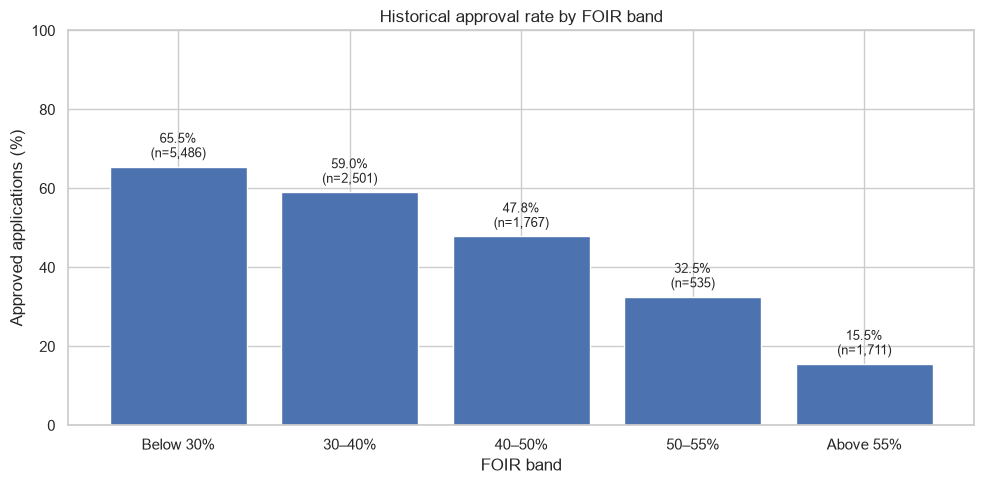

In [17]:
# Step 5.3D — Plot approval rates by FOIR band, with sample size on each bar.
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(foir_summary.index.astype(str), foir_summary["approval_rate_percent"])
ax.set_title("Historical approval rate by FOIR band")
ax.set_xlabel("FOIR band")
ax.set_ylabel("Approved applications (%)")
ax.set_ylim(0, 100)
for bar, (_, row) in zip(bars, foir_summary.iterrows()):
    ax.annotate(
        f"{row['approval_rate_percent']:.1f}%\n(n={int(row['applications']):,})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9,
    )
plt.tight_layout()
plt.show()

**Interpretation and provisional policy recommendation
The observed approval rate decreases as FOIR rises. In this dataset, it falls from 65.48% for FOIR below 30% to 47.82% in the 40–50% band, 32.52% in the 50–55% band, and 15.55% above 55%. This is a strong downward pattern, with approvals becoming notably less common beyond 50%.

Provisional policy recommendation: use 50% FOIR as an enhanced-review trigger, not a stand-alone automatic-decline rule. Applications above 50% should receive closer review of income stability, existing obligations, credit history, and other relevant factors. The historical data still contains approved applicants in the 50–55% band (174 approvals) and above 55% (266 approvals), so a rigid FOIR-only rejection would turn away people whom the historical credit team approved. The final auto-decline decision must instead be evaluated using the model's probability threshold and the assignment's 5% limit on historically approved cases among auto-declines.

Limitation: because missing income was filled with employment-type medians for this descriptive analysis, FOIR and loan-to-income for the 441 originally missing-income applications are estimates. The data represents historical decisions in a simulated dataset, not verified future loan repayment.**

# Phase 5 — Build the logistic regression pre-screener

**Objective:** predict the credit team's historical decision, with `Declined = 1` and `Approved = 0`, using exactly the features specified in the assignment. This is a supervised binary-classification problem.

The assignment requires an 80/20 stratified split with `random_state=42`, one-hot encoding for `employment_type` and `loan_purpose`, scaling of numeric features, accuracy, a confusion matrix, precision and recall for the Declined class, and coefficient interpretation.

**Important limitation:** the target is a historical analyst decision in a simulated dataset. It is not a measure of whether an applicant will repay a loan.

## 5.4A — Split first, then engineer model features

We create the stratified train/test split **before learning imputation values**. This prevents the test set from influencing training-time medians.

- `decision` is converted to 1 for `Declined` and 0 for `Approved`.
- The split uses `test_size=0.20`, `stratify=y`, and `random_state=42` so the target balance is preserved and the result is reproducible.
- The already documented income-unit correction is deterministic and is applied on the modelling copy. Missing income is then filled with the employment-type median calculated from the **training partition only** (with a training-set global-median fallback).
- FOIR and loan-to-income are calculated after this training-only income imputation.
- Missing `credit_score` values are not manually filled here. The modelling pipeline will learn the median from the training partition, while `is_ntc` preserves the missing-score signal.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

# Use the documented cleaning copy created in Phase 2. The original df_raw remains unchanged.
model_source = df_clean.copy()

y_all = model_source["decision"].map({"Approved": 0, "Declined": 1})
assert y_all.notna().all(), "Unexpected values found in decision; review target mapping."
y_all = y_all.astype(int)

train_idx, test_idx = train_test_split(
    model_source.index,
    test_size=0.20,
    stratify=y_all,
    random_state=42,
)
train_base = model_source.loc[train_idx].copy()
test_base = model_source.loc[test_idx].copy()
y_train = y_all.loc[train_idx]
y_test = y_all.loc[test_idx]

# Learn income imputation values from training data only.
income_medians_by_employment = train_base.groupby("employment_type")["monthly_income"].median()
training_global_income_median = train_base["monthly_income"].median()

def add_model_features(partition):
    """Create the requested affordability features using training-only income medians."""
    frame = partition.copy()
    employment_median = frame["employment_type"].map(income_medians_by_employment)
    frame["monthly_income_model"] = (
        frame["monthly_income"]
        .fillna(employment_median)
        .fillna(training_global_income_median)
    )
    frame["foir"] = (
        frame["existing_emi"] + frame["proposed_emi"]
    ) / frame["monthly_income_model"]
    frame["loan_to_income"] = frame["loan_amount"] / (
        frame["monthly_income_model"] * 12
    )
    frame["is_ntc"] = frame["credit_score"].isna().astype(int)
    return frame

train_model = add_model_features(train_base)
test_model = add_model_features(test_base)

feature_cols = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier", "employment_type", "loan_purpose"
]
numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]

# Guardrails: requested feature list only, correct split size, preserved NTC cases and finite engineered features.
assert len(train_model) == 9600 and len(test_model) == 2400
assert set(feature_cols).issubset(train_model.columns)
assert len(feature_cols) == 12
assert not set(["application_id", "application_date", "city", "gender", "decision"]).intersection(feature_cols)
assert train_model["foir"].notna().all() and np.isfinite(train_model["foir"]).all()
assert test_model["foir"].notna().all() and np.isfinite(test_model["foir"]).all()
assert train_model["loan_to_income"].notna().all() and np.isfinite(train_model["loan_to_income"]).all()
assert test_model["loan_to_income"].notna().all() and np.isfinite(test_model["loan_to_income"]).all()
assert train_model["is_ntc"].sum() + test_model["is_ntc"].sum() == int(model_source["credit_score"].isna().sum())

split_summary = pd.DataFrame({
    "partition": ["Train", "Test", "Full dataset"],
    "applications": [len(train_model), len(test_model), len(model_source)],
    "declined_count": [int(y_train.sum()), int(y_test.sum()), int(y_all.sum())],
    "declined_percent": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2), round(y_all.mean() * 100, 2)],
})
display(split_summary)
print("Training-only income medians by employment type (INR/month):")
display(income_medians_by_employment.rename("training_median_income").to_frame())
print("Training-set global income median (fallback): ₹{:,.0f}".format(training_global_income_median))
print("Missing monthly income after model-only imputation — train:", int(train_model["monthly_income_model"].isna().sum()))
print("Missing monthly income after model-only imputation — test:", int(test_model["monthly_income_model"].isna().sum()))
print("Train/test split and feature checks passed." )

,partition,applications,declined_count,declined_percent
0,Train,9600,4518,47.06
1,Test,2400,1129,47.04
2,Full dataset,12000,5647,47.06


Training-only income medians by employment type (INR/month):


,training_median_income
employment_type,
Business Owner,71000.0
Gig / Contract,28500.0
Salaried,50500.0
Self-Employed Professional,75250.0


Training-set global income median (fallback): ₹50,500
Missing monthly income after model-only imputation — train: 0
Missing monthly income after model-only imputation — test: 0
Train/test split and feature checks passed.


### Why this preparation matters

If we compute an imputation median from all 12,000 rows before splitting, information from the test data influences training preparation. The code above avoids that: test rows use values learned from the training partition, never medians calculated from the test partition. The test set therefore remains a more honest check of how the workflow might perform on unseen applications.

## 5.4B — Preprocessing pipeline and logistic regression

Numeric variables are median-imputed and standardised. Standardisation matters because features such as age, FOIR and credit score use different scales; it also makes numeric coefficient magnitudes more comparable per standard deviation. Categorical variables are imputed with the most frequent training value and one-hot encoded. We drop the first category for each categorical variable so categorical coefficients can be read relative to a defined reference category.

All learned preprocessing steps are inside a scikit-learn `Pipeline` and fitted only on the training data. The logistic regression's positive class is `Declined (1)`.

,metric,value,percent
0,Accuracy,0.790417,79.04
1,Precision — Declined class,0.790892,79.09
2,Recall — Declined class,0.753764,75.38


Confusion matrix — rows are actual historical decisions; columns are model predictions:


,Predicted Approved (0),Predicted Declined (1)
Actual Approved (0),1046,225
Actual Declined (1),278,851


Test applications: 2,400
Historically approved applications wrongly predicted as Declined: 225
Historically declined applications correctly predicted as Declined: 851
Historically declined applications predicted as Approved: 278
Among model-predicted declines, historically approved cases: 20.91%

Detailed classification report:
              precision    recall  f1-score   support

Approved (0)       0.79      0.82      0.81      1271
Declined (1)       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



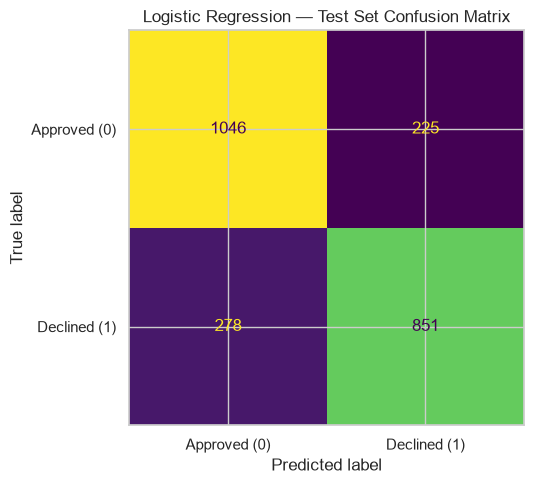

In [19]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42)),
])

logistic_model.fit(train_model[feature_cols], y_train)
y_pred = logistic_model.predict(test_model[feature_cols])
y_proba_declined = logistic_model.predict_proba(test_model[feature_cols])[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision_declined = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall_declined = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

metrics_summary = pd.DataFrame({
    "metric": ["Accuracy", "Precision — Declined class", "Recall — Declined class"],
    "value": [accuracy, precision_declined, recall_declined],
    "percent": [round(accuracy * 100, 2), round(precision_declined * 100, 2), round(recall_declined * 100, 2)],
})
display(metrics_summary)

cm_table = pd.DataFrame(
    cm,
    index=["Actual Approved (0)", "Actual Declined (1)"],
    columns=["Predicted Approved (0)", "Predicted Declined (1)"],
)
print("Confusion matrix — rows are actual historical decisions; columns are model predictions:")
display(cm_table)

# For target=Declined(1), cm[0, 1] are historically approved applications predicted as Declined.
wrongly_flagged_historically_approved = int(cm[0, 1])
correctly_identified_declines = int(cm[1, 1])
missed_historical_declines = int(cm[1, 0])
predicted_decline_count = int((y_pred == 1).sum())
wrong_share_of_predicted_declines = (
    wrongly_flagged_historically_approved / predicted_decline_count
    if predicted_decline_count else np.nan
)

print(f"Test applications: {len(y_test):,}")
print(f"Historically approved applications wrongly predicted as Declined: {wrongly_flagged_historically_approved:,}")
print(f"Historically declined applications correctly predicted as Declined: {correctly_identified_declines:,}")
print(f"Historically declined applications predicted as Approved: {missed_historical_declines:,}")
print(f"Among model-predicted declines, historically approved cases: {wrong_share_of_predicted_declines:.2%}")
print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["Approved (0)", "Declined (1)"], zero_division=0))

fig, ax = plt.subplots(figsize=(6.5, 5))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Approved (0)", "Declined (1)"])
display_cm.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Logistic Regression — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

### Interpret the confusion matrix in business language

With the requested target coding, **`cm[0, 1]` is the number of applications historically approved by the credit team that the model predicts as Declined**. This is the key error to watch before using any prediction to automatically decline an application. The reverse error, `cm[1, 0]`, counts historically declined cases the model would predict as Approved; it could send more cases to manual review or downstream assessment.

Do not describe a historically approved applicant as definitively “creditworthy”: this dataset records past decisions, not future repayment outcomes. The model reproduces historical decisions, and its predictions must not be treated as proof of a customer's ability to repay.

## 5.4C — Interpret the logistic regression coefficients

For this model, a **positive coefficient** pushes the estimated log-odds towards `Declined (1)`, while a **negative coefficient** pushes towards `Approved (0)`, holding the other encoded features constant. Numeric features were standardised, so their coefficients correspond to a one-standard-deviation increase. Categorical coefficients are relative to the dropped reference category: `Business Owner` for employment type and `Consumer Durables` for loan purpose.

Coefficient size is not the same as causation. These are conditional associations in this fitted model, not proof that changing a feature causes a credit decision.

In [20]:
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefficient_values = logistic_model.named_steps["classifier"].coef_.ravel()
coefficient_table = pd.DataFrame({
    "encoded_feature": feature_names,
    "coefficient": coefficient_values,
})
coefficient_table["direction"] = np.where(
    coefficient_table["coefficient"] > 0,
    "Pushes toward Declined",
    "Pushes away from Declined",
)
coefficient_table["odds_ratio_per_coefficient_unit"] = np.exp(coefficient_table["coefficient"])

print("Five largest positive coefficients — strongest fitted pushes towards Declined:")
top_decline_coefficients = coefficient_table.sort_values("coefficient", ascending=False).head(5).copy()
display(top_decline_coefficients.round(3))

print("Five largest absolute coefficients — strongest terms in either direction:")
top_absolute_coefficients = coefficient_table.reindex(
    coefficient_table["coefficient"].abs().sort_values(ascending=False).index
).head(5).copy()
display(top_absolute_coefficients.round(3))

print("Reference categories: employment_type = Business Owner; loan_purpose = Consumer Durables.")
print("Positive coefficients move predictions towards Declined; negative coefficients move predictions away from Declined.")

Five largest positive coefficients — strongest fitted pushes towards Declined:


,encoded_feature,coefficient,direction,odds_ratio_per_coefficient_unit
2,num__foir,1.223,Pushes toward Declined,3.397
4,num__delinquencies_24m,0.980,Pushes toward Declined,2.664
10,cat__employment_type_Gig / Contract,0.635,Pushes toward Declined,1.886
13,cat__loan_purpose_Debt Consolidation,0.508,Pushes toward Declined,1.662
1,num__is_ntc,0.381,Pushes toward Declined,1.464


Five largest absolute coefficients — strongest terms in either direction:


,encoded_feature,coefficient,direction,odds_ratio_per_coefficient_unit
2,num__foir,1.223,Pushes toward Declined,3.397
0,num__credit_score,-1.009,Pushes away from Declined,0.365
4,num__delinquencies_24m,0.980,Pushes toward Declined,2.664
10,cat__employment_type_Gig / Contract,0.635,Pushes toward Declined,1.886
13,cat__loan_purpose_Debt Consolidation,0.508,Pushes toward Declined,1.662


Reference categories: employment_type = Business Owner; loan_purpose = Consumer Durables.
Positive coefficients move predictions towards Declined; negative coefficients move predictions away from Declined.


## Phase 5 checkpoint and provisional conclusion

- The model uses the required 12 input features and excludes application identifiers, application date, city, gender, and the decision label from the predictors.
- Split: 80% training and 20% testing, stratified with `random_state=42`.
- The preprocessing pipeline fits numeric imputation, scaling, and categorical encoding on training data only.
- The confusion matrix explicitly quantifies historically approved applications that would be wrongly flagged as Declined at the default 0.50 cutoff.
- Coefficient tables report both the strongest decline-direction terms and the largest effects by absolute coefficient, with signs interpreted in business terms.

**Do not auto-decline based on the default 0.50 cutoff.** The next phase will calculate predicted decline probabilities at the assignment's seven thresholds (0.50 through 0.95) and select the threshold with the greatest coverage while keeping historically approved cases at or below 5% of the auto-decline group.

**Presentation takeaway:** this is a baseline classification model, not yet an operational decision rule. The threshold and fairness checks still have to be completed.

**Phase 6 — Choose a conservative auto-decline threshold**

We will use the fitted model's predicted probability of Declined (1) on the held-out test set. An application is considered for auto-decline only when its predicted decline probability is greater than or equal to the tested threshold.

The bank's constraint is: no more than 5% of applications auto-declined by the model may be applications the historical credit team Approved. This is a precision-like risk measure with a specific denominator: the auto-decline group. It is not the same as false-positive rate across all approved applications.

We will evaluate the seven thresholds specified in the brief. We will not assume that 0.50 is appropriate simply because it is the classifier's default cutoff.

In [21]:
# Step 5.5A — Evaluate each required threshold on held-out test applications
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
test_n = len(y_test)
threshold_rows = []

for threshold in thresholds:
    auto_decline_mask = y_proba_declined >= threshold
    auto_declined_count = int(auto_decline_mask.sum())
    historically_approved_among_auto_declines = int(((y_test == 0) & auto_decline_mask).sum())

    if auto_declined_count > 0:
        wrong_decline_share = historically_approved_among_auto_declines / auto_declined_count
    else:
        wrong_decline_share = np.nan

    threshold_rows.append({
        "threshold": threshold,
        "auto_declined_count": auto_declined_count,
        "auto_declined_percent_of_test": auto_declined_count / test_n * 100,
        "historically_approved_wrongly_auto_declined": historically_approved_among_auto_declines,
        "historically_approved_share_of_auto_declines_percent": wrong_decline_share * 100 if np.isfinite(wrong_decline_share) else np.nan,
        "meets_5pct_guardrail": bool(auto_declined_count > 0 and np.isfinite(wrong_decline_share) and wrong_decline_share <= 0.05),
    })

threshold_table = pd.DataFrame(threshold_rows)
# Round only for display; keep underlying percentages unrounded for the guardrail.
display(threshold_table.round({
    "threshold": 2,
    "auto_declined_percent_of_test": 2,
    "historically_approved_share_of_auto_declines_percent": 2,
}))

print(f"Held-out test applications: {test_n:,}")
print("Risk measure = historically Approved applications in the auto-decline group / all applications in the auto-decline group.")


,threshold,auto_declined_count,auto_declined_percent_of_test,historically_approved_wrongly_auto_declined,historically_approved_share_of_auto_declines_percent,meets_5pct_guardrail
0,0.50,1076,44.83,225,20.91,False
1,0.60,903,37.62,152,16.83,False
2,0.70,740,30.83,90,12.16,False
3,0.80,562,23.42,39,6.94,False
4,0.85,472,19.67,28,5.93,False
5,0.90,364,15.17,17,4.67,True
6,0.95,240,10.00,5,2.08,True


Held-out test applications: 2,400
Risk measure = historically Approved applications in the auto-decline group / all applications in the auto-decline group.


How to read this table
- Auto-declined count / percent: how many test applications cross the probability threshold.
- Historically Approved among auto-declines: the number of cases that would be incorrectly auto-declined relative to the historical decision label.
- Historically Approved share of auto-declines: the percentage used for the bank's 5% guardrail.
- Meets guardrail: True only when at least one application would be auto-declined and the historically Approved share is at most 5%. A threshold that sends no applications to auto-decline is not treated as a useful operating choice.
Remember: “historically Approved” is the label available in this simulated dataset. It is not independent proof of repayment ability or creditworthiness.

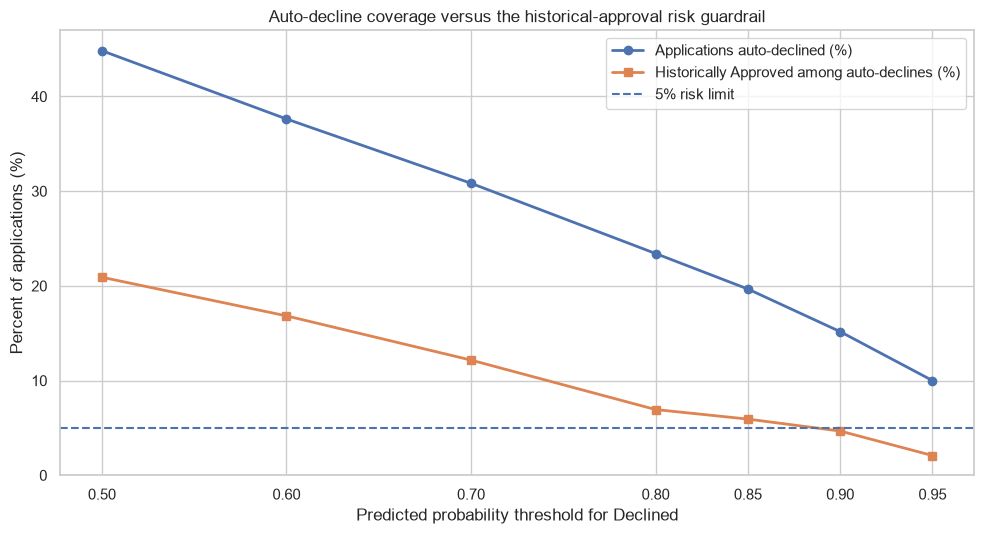

In [22]:
# Step 5.5B — Plot both required percentages against the threshold
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    threshold_table["threshold"],
    threshold_table["auto_declined_percent_of_test"],
    marker="o", linewidth=2, label="Applications auto-declined (%)"
)
ax.plot(
    threshold_table["threshold"],
    threshold_table["historically_approved_share_of_auto_declines_percent"],
    marker="s", linewidth=2, label="Historically Approved among auto-declines (%)"
)
ax.axhline(5, linestyle="--", linewidth=1.5, label="5% risk limit")
ax.set_title("Auto-decline coverage versus the historical-approval risk guardrail")
ax.set_xlabel("Predicted probability threshold for Declined")
ax.set_ylabel("Percent of applications (%)")
ax.set_xticks(thresholds)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()


In [23]:
# Step 5.5C — Select the threshold with maximum coverage subject to the 5% rule
eligible_thresholds = threshold_table.loc[threshold_table["meets_5pct_guardrail"]].copy()

if eligible_thresholds.empty:
    recommended_threshold = None
    print("NO TESTED THRESHOLD SATISFIES THE 5% RULE WITH POSITIVE AUTO-DECLINE COVERAGE.")
    print("Do not auto-decline applications using any of these tested thresholds. The model or operating policy needs further work and independent validation.")
else:
    # The required operating choice is the eligible threshold that covers the most applications.
    # If coverage ties, prefer the higher threshold (more conservative decision boundary).
    eligible_thresholds = eligible_thresholds.sort_values(
        ["auto_declined_count", "threshold"], ascending=[False, False]
    )
    recommended_row = eligible_thresholds.iloc[0]
    recommended_threshold = float(recommended_row["threshold"])
    coverage = float(recommended_row["auto_declined_percent_of_test"])
    wrong_share_percent = float(recommended_row["historically_approved_share_of_auto_declines_percent"])
    print(f"Recommended threshold from the required grid: {recommended_threshold:.2f}")
    print(f"Test applications auto-declined: {int(recommended_row['auto_declined_count']):,} of {test_n:,} ({coverage:.2f}%)")
    print(f"Historically Approved among auto-declines: {int(recommended_row['historically_approved_wrongly_auto_declined']):,} ({wrong_share_percent:.2f}%)")
    print("Guardrail check:", "PASS" if wrong_share_percent <= 5.0 else "FAIL")


Recommended threshold from the required grid: 0.90
Test applications auto-declined: 364 of 2,400 (15.17%)
Historically Approved among auto-declines: 17 (4.67%)
Guardrail check: PASS


**Business translation — expected monthly analyst time**

In [24]:
# Step 5.5D — Monthly capacity estimate at the selected threshold
monthly_applications = 3000
manual_review_minutes = 25

if recommended_threshold is None:
    monthly_capacity_summary = pd.DataFrame([{
        "recommended_threshold": "None — guardrail not met",
        "estimated_monthly_auto_declines": 0,
        "estimated_monthly_historically_approved_cases_auto_declined": 0,
        "estimated_analyst_hours_potentially_freed": 0.0,
        "interpretation": "No tested threshold is eligible; do not automate auto-declines.",
    }])
else:
    selected = threshold_table.loc[threshold_table["threshold"].eq(recommended_threshold)].iloc[0]
    coverage_fraction = selected["auto_declined_percent_of_test"] / 100
    wrong_fraction_of_test = selected["historically_approved_wrongly_auto_declined"] / test_n
    est_monthly_auto_declines = monthly_applications * coverage_fraction
    est_monthly_historical_approvals_auto_declined = monthly_applications * wrong_fraction_of_test
    est_hours_freed = est_monthly_auto_declines * manual_review_minutes / 60
    monthly_capacity_summary = pd.DataFrame([{
        "recommended_threshold": recommended_threshold,
        "estimated_monthly_auto_declines": round(est_monthly_auto_declines),
        "estimated_monthly_historically_approved_cases_auto_declined": round(est_monthly_historical_approvals_auto_declined),
        "estimated_analyst_hours_potentially_freed": round(est_hours_freed, 1),
        "interpretation": "Scenario estimate based on held-out test coverage; validate before operational use.",
    }])

display(monthly_capacity_summary)

if recommended_threshold is not None:
    assert float(selected["historically_approved_share_of_auto_declines_percent"]) <= 5.0
    assert int(selected["auto_declined_count"]) > 0


,recommended_threshold,estimated_monthly_auto_declines,estimated_monthly_historically_approved_cases_auto_declined,estimated_analyst_hours_potentially_freed,interpretation
0,0.9,455,21,189.6,Scenario estimate based on held-out test cover...


Phase 6 checkpoint and decision caveats
Before recommending any operational automation, confirm the following:
1. The selected threshold comes from the seven thresholds mandated by the assignment, and coverage is maximised only among thresholds meeting the 5% guardrail.
2. The risk percentage's denominator is the set of applications auto-declined, not all applications and not all historically Approved applications.
3. The monthly hours are estimates derived from test-set coverage, 3,000 monthly applications, and 25 minutes per manual review.
4. This exercise chooses a threshold on the held-out test set because that is what the assignment specifies. In a production-grade study, threshold selection should use a validation set, with a separate untouched test set reserved for final performance assessment; model stability, calibration, drift and fairness should also be checked.
5. Because the label is a historical analyst decision in a simulated dataset, this analysis measures agreement with historical decisions—not default prediction or repayment outcomes. Any real credit decision requires appropriate policy, compliance and human oversight.

**Phase 7 — Fairness evaluation**

Assignment section 5.6. Excluding gender from the model does not guarantee fairness. We will compare historical approval outcomes by gender, then within employment type, examine income and employment mix, and evaluate the fitted model's auto-decline rate by gender at the threshold selected in Phase 6.

Important interpretation limit: decision is the historical credit team's decision in a simulated dataset, not a verified repayment outcome. These checks are descriptive diagnostics, not proof of legal or ethical fairness.

Historical approval rates by gender

In [25]:
# Step 5.6A — Overall historical approval rate by gender
gender_history = (
    df_raw.groupby("gender", dropna=False)
    .agg(
        applications=("application_id", "size"),
        approved=("decision", lambda s: s.eq("Approved").sum()),
        declined=("decision", lambda s: s.eq("Declined").sum()),
    )
)
gender_history["approval_rate_percent"] = gender_history["approved"] / gender_history["applications"] * 100
gender_history["decline_rate_percent"] = gender_history["declined"] / gender_history["applications"] * 100
display(gender_history.round(2))

# Absolute overall approval-rate gap in percentage points (largest minus smallest group).
overall_approval_gap_pp = gender_history["approval_rate_percent"].max() - gender_history["approval_rate_percent"].min()
print(f"Overall historical approval-rate gap: {overall_approval_gap_pp:.2f} percentage points.")
assert gender_history["applications"].sum() == len(df_raw), "Gender summary did not retain every application."

,applications,approved,declined,approval_rate_percent,decline_rate_percent
gender,,,,,
Female,3795,1914,1881,50.43,49.57
Male,8205,4439,3766,54.10,45.90


Overall historical approval-rate gap: 3.67 percentage points.


**Check approval rates within employment type**

difference in overall approval rates can reflect differences in the types of jobs applicants have, not only differences in decisions within the same employment category. This table lets us compare gender groups within each employment type. A within-group gap can still reflect other applicant characteristics and does not establish that gender caused the decision.

In [26]:
# Step 5.6B — Historical approval rates by gender within employment type
gender_employment_history = (
    df_raw.groupby(["employment_type", "gender"], dropna=False)
    .agg(
        applications=("application_id", "size"),
        approved=("decision", lambda s: s.eq("Approved").sum()),
    )
)
gender_employment_history["approval_rate_percent"] = (
    gender_employment_history["approved"] / gender_employment_history["applications"] * 100
)
display(gender_employment_history.round(2))

approval_rate_pivot = gender_employment_history["approval_rate_percent"].unstack("gender")
if {"Female", "Male"}.issubset(approval_rate_pivot.columns):
    approval_rate_pivot["female_minus_male_pp"] = approval_rate_pivot["Female"] - approval_rate_pivot["Male"]
print("\nApproval rates by employment type (percent):")
display(approval_rate_pivot.round(2))
assert gender_employment_history["applications"].sum() == len(df_raw), "Gender-by-employment summary lost applications."

applications  approved  \
employment_type            gender                           
Business Owner             Female           370       191   
                           Male            1379       704   
Gig / Contract             Female           811       281   
                           Male             955       336   
Salaried                   Female          2150      1221   
                           Male            4907      2898   
Self-Employed Professional Female           464       221   
                           Male             964       501   

                                   approval_rate_percent  
employment_type            gender                         
Business Owner             Female                  51.62  
                           Male                    51.05  
Gig / Contract             Female                  34.65  
                           Male                    35.18  
Salaried                   Female                  56.79  
                           Male                    59.06  
Self-Employed Professional Female                  47.63  
                           Male                    51.97


Approval rates by employment type (percent):


gender,Female,Male,female_minus_male_pp
employment_type,,,
Business Owner,51.62,51.05,0.57
Gig / Contract,34.65,35.18,-0.53
Salaried,56.79,59.06,-2.27
Self-Employed Professional,47.63,51.97,-4.34


**Compare income and Gig / Contract representation**

We use the cleaned income values from Phase 2, which corrects only the narrowly flagged suspected annual-income entries. The median excludes rows whose income remains missing; we report the non-missing count so the denominator is transparent. Gig / Contract share is calculated over all applications in each gender group, without income imputation.

In [27]:
# Step 5.6C — Median monthly income and Gig / Contract share by gender
fairness_income_source = df_clean.copy()
gender_income_mix = fairness_income_source.groupby("gender", dropna=False).agg(
    applications=("application_id", "size"),
    nonmissing_income_count=("monthly_income", "count"),
    median_monthly_income_inr=("monthly_income", "median"),
)
gig_counts = (
    fairness_income_source.assign(is_gig_contract=fairness_income_source["employment_type"].eq("Gig / Contract"))
    .groupby("gender", dropna=False)
    .agg(gig_contract_applications=("is_gig_contract", "sum"))
)
gender_income_mix = gender_income_mix.join(gig_counts)
gender_income_mix["gig_contract_share_percent"] = (
    gender_income_mix["gig_contract_applications"] / gender_income_mix["applications"] * 100
)
display(gender_income_mix.round(2))
assert gender_income_mix["applications"].sum() == len(fairness_income_source), "Gender income summary lost applications."

,applications,nonmissing_income_count,median_monthly_income_inr,gig_contract_applications,gig_contract_share_percent
gender,,,,,
Female,3795,3672,44000.0,811,21.37
Male,8205,7887,54000.0,955,11.64


**Auto-decline rate by gender at the selected threshold**

The model did not receive gender as an input feature. Here we bring gender back only for post-model auditing. We use the exact held-out test applications and the Phase 6 recommended threshold. The auto-decline rate is auto-declined applicants in a gender group ÷ all test applicants in that group. We also show the historical-approval share among each group's auto-declines, using the same denominator definition as the 5% guardrail.

In [28]:
# Step 5.6D — Audit outcomes by gender without using gender to train the model
if recommended_threshold is None:
    raise RuntimeError("No threshold passed the Phase 6 guardrail; do not compute an auto-decline recommendation.")

# Index alignment is explicit: test_model, y_test, and model probabilities correspond to the same held-out records.
test_fairness = pd.DataFrame(index=test_model.index)
test_fairness["gender"] = test_model["gender"].astype("object")
test_fairness["employment_type"] = test_model["employment_type"].astype("object")
test_fairness["historical_decision"] = y_test.reindex(test_model.index).map({0: "Approved", 1: "Declined"})
test_fairness["probability_declined"] = pd.Series(y_proba_declined, index=test_model.index)
test_fairness["auto_decline"] = test_fairness["probability_declined"].ge(recommended_threshold)

gender_auto_decline = test_fairness.groupby("gender", dropna=False).agg(
    test_applications=("auto_decline", "size"),
    auto_declined=("auto_decline", "sum"),
)
gender_auto_decline["auto_decline_rate_percent"] = (
    gender_auto_decline["auto_declined"] / gender_auto_decline["test_applications"] * 100
)
wrongly_auto_declined_by_gender = (
    test_fairness.loc[test_fairness["auto_decline"] & test_fairness["historical_decision"].eq("Approved")]
    .groupby("gender").size()
)
gender_auto_decline["historically_approved_auto_declined"] = wrongly_auto_declined_by_gender.reindex(gender_auto_decline.index, fill_value=0)
gender_auto_decline["historically_approved_share_of_auto_declines_percent"] = np.where(
    gender_auto_decline["auto_declined"].gt(0),
    gender_auto_decline["historically_approved_auto_declined"] / gender_auto_decline["auto_declined"] * 100,
    np.nan,
)
display(gender_auto_decline.round(2))
auto_decline_gap_pp = (
    gender_auto_decline["auto_decline_rate_percent"].max() - gender_auto_decline["auto_decline_rate_percent"].min()
)
print(f"Recommended threshold: {recommended_threshold:.2f}")
print(f"Auto-decline-rate gap across gender groups: {auto_decline_gap_pp:.2f} percentage points.")
print(f"Total test-set auto-declines checked: {int(test_fairness['auto_decline'].sum()):,}")
assert int(test_fairness["auto_decline"].sum()) == int(
    threshold_table.loc[threshold_table["threshold"].eq(recommended_threshold), "auto_declined_count"].iloc[0]
), "Gender audit auto-decline count does not match the Phase 6 threshold table."

,test_applications,auto_declined,auto_decline_rate_percent,historically_approved_auto_declined,historically_approved_share_of_auto_declines_percent
gender,,,,,
Female,750,117,15.60,4,3.42
Male,1650,247,14.97,13,5.26


Recommended threshold: 0.90
Auto-decline-rate gap across gender groups: 0.63 percentage points.
Total test-set auto-declines checked: 364


**Fairness interpretation (draft from this dataset)**

In [29]:
# Generate a data-backed draft interpretation; review it before using it in the final briefing.
if {"Female", "Male"}.issubset(gender_history.index):
    female_approval = float(gender_history.loc["Female", "approval_rate_percent"])
    male_approval = float(gender_history.loc["Male", "approval_rate_percent"])
    female_median_income = float(gender_income_mix.loc["Female", "median_monthly_income_inr"])
    male_median_income = float(gender_income_mix.loc["Male", "median_monthly_income_inr"])
    female_gig_share = float(gender_income_mix.loc["Female", "gig_contract_share_percent"])
    male_gig_share = float(gender_income_mix.loc["Male", "gig_contract_share_percent"])
    female_auto_rate = float(gender_auto_decline.loc["Female", "auto_decline_rate_percent"])
    male_auto_rate = float(gender_auto_decline.loc["Male", "auto_decline_rate_percent"])
    print(
        f"In the historical data, the approval rate was {female_approval:.2f}% for Female applicants and "
        f"{male_approval:.2f}% for Male applicants, a difference of {female_approval - male_approval:+.2f} percentage points (Female minus Male). "
        f"Median monthly income was ₹{female_median_income:,.0f} for Female applicants and ₹{male_median_income:,.0f} for Male applicants; "
        f"Gig / Contract representation was {female_gig_share:.2f}% versus {male_gig_share:.2f}%. "
        f"At threshold {recommended_threshold:.2f}, model auto-decline rates were {female_auto_rate:.2f}% for Female applicants and "
        f"{male_auto_rate:.2f}% for Male applicants (gap {female_auto_rate - male_auto_rate:+.2f} percentage points, Female minus Male). "
        "Gender was excluded from training, but income and employment variables can still act as proxies, so this is not proof of fairness; further policy, proxy, outcome and ongoing monitoring checks are needed."
    )
else:
    print("Review the gender categories in the tables and adapt this draft to the categories present in the dataset.")

In the historical data, the approval rate was 50.43% for Female applicants and 54.10% for Male applicants, a difference of -3.67 percentage points (Female minus Male). Median monthly income was ₹44,000 for Female applicants and ₹54,000 for Male applicants; Gig / Contract representation was 21.37% versus 11.64%. At threshold 0.90, model auto-decline rates were 15.60% for Female applicants and 14.97% for Male applicants (gap +0.63 percentage points, Female minus Male). Gender was excluded from training, but income and employment variables can still act as proxies, so this is not proof of fairness; further policy, proxy, outcome and ongoing monitoring checks are needed.


The historical approval rate was 50.43% for Female applicants and 54.10% for Male applicants, a 3.67 percentage-point difference, and female applicants also had lower median monthly income (₹44,000 versus ₹54,000) and a higher Gig / Contract share (21.37% versus 11.64%). Within employment type, the gap is not uniform: female approval is slightly higher for Business Owners, but lower for Salaried and Self-Employed Professional applicants. At the selected 0.90 threshold, auto-decline rates are 15.60% for Female applicants and 14.97% for Male applicants; this 0.63-point gap is smaller than the 3.67-point historical decline-rate gap in this sample, but the metrics describe different processes and do not prove that the model corrected bias. Gender was excluded from training, but income and employment type may act as proxies; the bank should not use gender as a model feature without explicit legal/compliance review, should retain lawfully permitted group data for fairness auditing, and should validate against real outcomes before operational use.

Additional subgroup caution: although the overall test-set guardrail passes at 4.67%, historically Approved cases make up 3.42% of Female auto-declines (4/117) and 5.26% of Male auto-declines (13/247). The 5% assignment limit is overall, not group-specific, but this subgroup result is a reason for further review before deployment.

**Phase 8 — Credit Policy Briefing and final submission**

This final section translates the analysis into the decision the Credit Policy Analyst needs. It prints a concise audit of the selected threshold, projected workload impact, strongest fitted model terms, and fairness diagnostics so the briefing can be checked against the outputs above.

Important interpretation boundary: this dataset is simulated and the target is a historical analyst decision, not an observed repayment/default outcome. Monthly impacts are scenario estimates, not guaranteed savings. Threshold 0.90 was selected from the seven values requested by the assignment using the held-out test set; a production study should select its threshold on a validation set and preserve a separate untouched final test set.

In [30]:
# Phase 8 — Final consistency checks and briefing values
assert len(df_raw) == 12_000, "Dataset row count differs from the documented assignment dataset."
assert len(y_test) == 2_400, "Expected an 80/20 hold-out split of 12,000 applications."
assert recommended_threshold is not None, "No threshold passed the assignment's 5% guardrail."

selected_threshold_row = threshold_table.loc[
    threshold_table["threshold"].eq(recommended_threshold)
].iloc[0]
assert bool(selected_threshold_row["meets_5pct_guardrail"]), "Selected threshold does not pass the guardrail."

# Display the full threshold table so the assignment evidence is visible in the final notebook.
threshold_submission_view = threshold_table[[
    "threshold",
    "auto_declined_count",
    "auto_declined_percent_of_test",
    "historically_approved_wrongly_auto_declined",
    "historically_approved_share_of_auto_declines_percent",
    "meets_5pct_guardrail",
]].copy()
print("REQUIRED THRESHOLD COMPARISON")
display(threshold_submission_view.round({
    "threshold": 2,
    "auto_declined_percent_of_test": 2,
    "historically_approved_share_of_auto_declines_percent": 2,
}))
print("\nFull threshold table values:")
print(threshold_submission_view.to_string(index=False, formatters={
    "threshold": lambda x: f"{x:.2f}",
    "auto_declined_percent_of_test": lambda x: f"{x:.2f}%",
    "historically_approved_share_of_auto_declines_percent": lambda x: f"{x:.2f}%",
}))

monthly_apps = 3_000
review_minutes = 25
coverage_pct = float(selected_threshold_row["auto_declined_percent_of_test"])
wrong_count_test = int(selected_threshold_row["historically_approved_wrongly_auto_declined"])
auto_count_test = int(selected_threshold_row["auto_declined_count"])
wrong_share_pct = float(selected_threshold_row["historically_approved_share_of_auto_declines_percent"])
monthly_auto_declines = round(monthly_apps * coverage_pct / 100)
monthly_historically_approved_cases = round(monthly_apps * wrong_count_test / len(y_test))
monthly_hours_freed = monthly_apps * coverage_pct / 100 * review_minutes / 60

print("\nSELECTED THRESHOLD AND MONTHLY SCENARIO")
print(f"Threshold: {recommended_threshold:.2f}")
print(f"Held-out test auto-declines: {auto_count_test:,}/{len(y_test):,} ({coverage_pct:.2f}%)")
print(f"Historically Approved among auto-declines: {wrong_count_test:,}/{auto_count_test:,} ({wrong_share_pct:.2f}%)")
print(f"Estimated monthly auto-declines: {monthly_auto_declines:,} of {monthly_apps:,}")
print(f"Potential analyst hours freed per month: {monthly_hours_freed:.1f}")
print(f"Estimated monthly cases that were historically Approved but auto-declined: {monthly_historically_approved_cases:,} (scenario estimate, not confirmed creditworthy cases)")

# The two largest positive coefficients have the strongest fitted pushes towards Declined.
top_two_positive = coefficient_table.sort_values("coefficient", ascending=False).head(2).copy()
print("\nTWO STRONGEST POSITIVE COEFFICIENTS")
display(top_two_positive[["encoded_feature", "coefficient", "direction"]].round(3))
foir_coef = float(coefficient_table.loc[coefficient_table["encoded_feature"].eq("num__foir"), "coefficient"].iloc[0])
delinquency_coef = float(coefficient_table.loc[coefficient_table["encoded_feature"].eq("num__delinquencies_24m"), "coefficient"].iloc[0])

# Fairness signals, including group-specific historical-approval shares among auto-declines.
female_approval_rate = float(gender_history.loc["Female", "approval_rate_percent"])
male_approval_rate = float(gender_history.loc["Male", "approval_rate_percent"])
female_auto_rate = float(gender_auto_decline.loc["Female", "auto_decline_rate_percent"])
male_auto_rate = float(gender_auto_decline.loc["Male", "auto_decline_rate_percent"])
female_wrong_share = float(gender_auto_decline.loc["Female", "historically_approved_share_of_auto_declines_percent"])
male_wrong_share = float(gender_auto_decline.loc["Male", "historically_approved_share_of_auto_declines_percent"])
ntc_count = int(df_clean["is_ntc"].sum())
ntc_share = float(df_clean["is_ntc"].mean() * 100)

print("\nFAIRNESS CHECK SUMMARY")
print(f"Historical approval rates: Female {female_approval_rate:.2f}%; Male {male_approval_rate:.2f}%")
print(f"Auto-decline rates at threshold {recommended_threshold:.2f}: Female {female_auto_rate:.2f}%; Male {male_auto_rate:.2f}%")
print(f"Historically Approved share among subgroup auto-declines: Female {female_wrong_share:.2f}%; Male {male_wrong_share:.2f}%")
print(f"New-to-credit applicants: {ntc_count:,} ({ntc_share:.2f}% of the dataset)")

assert round(accuracy * 100, 2) == 79.04
assert round(wrong_share_pct, 2) <= 5.00
assert auto_count_test == int(test_fairness["auto_decline"].sum())
print("\nFinal consistency checks passed.")

REQUIRED THRESHOLD COMPARISON


,threshold,auto_declined_count,auto_declined_percent_of_test,historically_approved_wrongly_auto_declined,historically_approved_share_of_auto_declines_percent,meets_5pct_guardrail
0,0.50,1076,44.83,225,20.91,False
1,0.60,903,37.62,152,16.83,False
2,0.70,740,30.83,90,12.16,False
3,0.80,562,23.42,39,6.94,False
4,0.85,472,19.67,28,5.93,False
5,0.90,364,15.17,17,4.67,True
6,0.95,240,10.00,5,2.08,True



Full threshold table values:
threshold  auto_declined_count auto_declined_percent_of_test  historically_approved_wrongly_auto_declined historically_approved_share_of_auto_declines_percent  meets_5pct_guardrail
     0.50                 1076                        44.83%                                          225                                               20.91%                 False
     0.60                  903                        37.62%                                          152                                               16.83%                 False
     0.70                  740                        30.83%                                           90                                               12.16%                 False
     0.80                  562                        23.42%                                           39                                                6.94%                 False
     0.85                  472                        19.67%     

,encoded_feature,coefficient,direction
2,num__foir,1.223,Pushes toward Declined
4,num__delinquencies_24m,0.980,Pushes toward Declined



FAIRNESS CHECK SUMMARY
Historical approval rates: Female 50.43%; Male 54.10%
Auto-decline rates at threshold 0.90: Female 15.60%; Male 14.97%
Historically Approved share among subgroup auto-declines: Female 3.42%; Male 5.26%
New-to-credit applicants: 1,039 (8.66% of the dataset)

Final consistency checks passed.


**Credit Policy Briefing**

Using the seven required probability thresholds, I recommend 0.90 for a carefully monitored pilot: 364 of 2,400 test applications (15.17%) would be auto-declined, and 17 of those were historically Approved (4.67%), meeting the assignment's overall 5% guardrail. Applied to 3,000 monthly applications, this corresponds to approximately 455 applications and 189.6 analyst hours potentially freed per month; around 21 historically Approved cases per month could also be auto-declined if test-set proportions held, so these are scenario estimates rather than guaranteed outcomes. The two strongest positive fitted coefficients pushing toward Declined are FOIR (+1.223) and delinquencies in the past 24 months (+0.980), consistent with higher repayment burden and recent missed payments being associated with historical declines. The model should not yet be trusted to make stand-alone decisions for new-to-credit applicants: 1,039 applications (8.66%) have no recorded credit score, and the dataset has historical decisions rather than verified repayment outcomes. Fairness checks show historical approval rates of 50.43% for Female and 54.10% for Male applicants; while test-set auto-decline rates differed by 0.63 percentage points, the historically Approved share among Male auto-declines was 5.26% versus 3.42% among Female auto-declines, so subgroup outcomes need further review. Before going live, obtain verified repayment/default outcomes, use a validation set for threshold selection and an untouched test set for final evaluation, and require appropriate policy/compliance review, human oversight, and ongoing fairness monitoring.